# Laboratory Assignment 8: High-Performance Big Data Analytics Using R

# Roll No: 24102A2005
# Name: Sajiya Shaikh

## 1. Problem Statement

The NYC Taxi and Limousine Commission generates millions of taxi-trip records. The objective is to build a high-performance and scalable analytics solution in R and compare conventional, optimized, functional, vectorized, sequential, and parallel approaches.

## 2. Install and Load Required Packages

In [1]:
required_packages <- c("data.table","ggplot2","lubridate","foreach","doParallel","microbenchmark","purrr","arrow")
for (p in required_packages) {
  if (!requireNamespace(p, quietly=TRUE)) install.packages(p, repos="https://cloud.r-project.org")
}
library(data.table)
library(ggplot2)
library(lubridate)
library(foreach)
library(doParallel)
library(microbenchmark)
library(purrr)
library(arrow)
cat("Packages loaded successfully.\n")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘iterators’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘assertthat’



Attaching package: ‘data.table’


The following object is masked from ‘package:base’:

    %notin%



Attaching package: ‘lubridate’


The following objects are masked from ‘package:data.table’:

    hour, isoweek, isoyear, mday, minute, month, quarter, second, wday,
    week, yday, year


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union


Loading required package: iterators

Loading required package: parallel


Attaching package: ‘purrr’


The following objects are masked from ‘package:foreach’:

    accumulate, when


The foll

Packages loaded successfully.


## 3. Data Acquisition

A sufficiently large monthly subset of the official NYC TLC Yellow Taxi Trip Records is downloaded for analysis.

In [2]:
data_dir <- "nyc_taxi_data"
dir.create(data_dir, showWarnings=FALSE)
months <- c("2024-01","2024-02")

download_taxi_month <- function(month) {
  url <- paste0("https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_",month,".parquet")
  dest <- file.path(data_dir,paste0("yellow_tripdata_",month,".parquet"))
  if (!file.exists(dest)) download.file(url,dest,mode="wb")
  dest
}
files <- vapply(months, download_taxi_month, character(1))
print(files)

                                        2024-01 
"nyc_taxi_data/yellow_tripdata_2024-01.parquet" 
                                        2024-02 
"nyc_taxi_data/yellow_tripdata_2024-02.parquet" 


## 4. Read the Taxi Data

In [3]:
taxi_list <- lapply(files, function(f) as.data.table(read_parquet(f)))
taxi <- rbindlist(taxi_list, fill=TRUE)
cat("Rows:",nrow(taxi),"\n")
cat("Columns:",ncol(taxi),"\n")
print(names(taxi))

Rows: 5972150 
Columns: 19 
 [1] "VendorID"              "tpep_pickup_datetime"  "tpep_dropoff_datetime"
 [4] "passenger_count"       "trip_distance"         "RatecodeID"           
 [7] "store_and_fwd_flag"    "PULocationID"          "DOLocationID"         
[10] "payment_type"          "fare_amount"           "extra"                
[13] "mta_tax"               "tip_amount"            "tolls_amount"         
[16] "improvement_surcharge" "total_amount"          "congestion_surcharge" 
[19] "Airport_fee"          


## 5. Inspect Structure, Dimensions and Summary Statistics

In [4]:
str(taxi)
dim(taxi)
summary(taxi)
cat("\nMissing values by column:\n")
print(sort(colSums(is.na(taxi)),decreasing=TRUE))

Classes ‘data.table’ and 'data.frame':	5972150 obs. of  19 variables:
 $ VendorID             : int  2 1 1 1 1 1 2 1 2 2 ...
 $ tpep_pickup_datetime : POSIXct, format: "2024-01-01 00:57:55" "2024-01-01 00:03:00" ...
 $ tpep_dropoff_datetime: POSIXct, format: "2024-01-01 01:17:43" "2024-01-01 00:09:36" ...
 $ passenger_count      : int  1 1 1 1 1 1 2 0 1 1 ...
 $ trip_distance        : num  1.72 1.8 4.7 1.4 0.8 ...
 $ RatecodeID           : int  1 1 1 1 1 1 1 1 1 1 ...
 $ store_and_fwd_flag   : chr  "N" "N" "N" "N" ...
 $ PULocationID         : int  186 140 236 79 211 148 138 246 161 113 ...
 $ DOLocationID         : int  79 236 79 211 148 141 181 231 261 113 ...
 $ payment_type         : int  2 1 1 1 1 1 1 2 2 2 ...
 $ fare_amount          : num  17.7 10 23.3 10 7.9 29.6 45.7 25.4 31 3 ...
 $ extra                : num  1 3.5 3.5 3.5 3.5 3.5 6 3.5 1 1 ...
 $ mta_tax              : num  0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 ...
 $ tip_amount           : num  0 3.75 3 2 3.2 6.9 10 0 0 

[1] 5972150      19

    VendorID     tpep_pickup_datetime          tpep_dropoff_datetime        
 Min.   :1.000   Min.   :2002-12-31 22:59:39   Min.   :2002-12-31 23:05:41  
 1st Qu.:2.000   1st Qu.:2024-01-17 12:38:32   1st Qu.:2024-01-17 12:56:59  
 Median :2.000   Median :2024-02-01 10:13:11   Median :2024-02-01 10:30:28  
 Mean   :1.755   Mean   :2024-02-01 00:27:21   Mean   :2024-02-01 00:43:09  
 3rd Qu.:2.000   3rd Qu.:2024-02-15 19:25:02   3rd Qu.:2024-02-15 19:40:37  
 Max.   :6.000   Max.   :2024-03-01 00:01:37   Max.   :2024-03-01 23:24:42  
                                                                            
 passenger_count  trip_distance         RatecodeID     store_and_fwd_flag 
 Min.   :0.000    Min.   :0.000e+00   Min.   : 1.000   Length   :5972150  
 1st Qu.:1.000    1st Qu.:1.000e+00   1st Qu.: 1.000   N.unique :      2  
 Median :1.000    Median :1.690e+00   Median : 1.000   N.blank  :      0  
 Mean   :1.333    Mean   :3.757e+00   Mean   : 2.092   Min.nchar:      1  
 3rd Qu.:


Missing values by column:
      passenger_count            RatecodeID    store_and_fwd_flag 
               325772                325772                325772 
 congestion_surcharge           Airport_fee              VendorID 
               325772                325772                     0 
 tpep_pickup_datetime tpep_dropoff_datetime         trip_distance 
                    0                     0                     0 
         PULocationID          DOLocationID          payment_type 
                    0                     0                     0 
          fare_amount                 extra               mta_tax 
                    0                     0                     0 
           tip_amount          tolls_amount improvement_surcharge 
                    0                     0                     0 
         total_amount 
                    0 


## 6. Data Cleaning and Preparation

Missing, duplicate, inconsistent, and invalid records are handled. Invalid passenger counts, distances, fares, totals, and timestamps are removed.

In [5]:
before <- nrow(taxi)
taxi[, pickup_datetime := as.POSIXct(tpep_pickup_datetime,tz="UTC")]
taxi[, dropoff_datetime := as.POSIXct(tpep_dropoff_datetime,tz="UTC")]
taxi <- unique(taxi)
taxi <- taxi[
  !is.na(pickup_datetime) & !is.na(dropoff_datetime) &
  !is.na(PULocationID) & !is.na(DOLocationID) &
  !is.na(trip_distance) & !is.na(fare_amount) &
  !is.na(total_amount) & trip_distance > 0 &
  fare_amount >= 0 & total_amount >= 0 & passenger_count > 0
]
cat("Rows before:",before,"\nRows after:",nrow(taxi),"\nRows removed:",before-nrow(taxi),"\n")

Rows before: 5972150 
Rows after: 5444106 
Rows removed: 528044 


## 7. Extract Temporal Attributes

In [6]:
taxi[, hour := hour(pickup_datetime)]
taxi[, day := day(pickup_datetime)]
taxi[, day_of_week := wday(pickup_datetime,label=TRUE,abbr=FALSE)]
taxi[, month := month(pickup_datetime,label=TRUE,abbr=FALSE)]
taxi[, month_num := month(pickup_datetime)]
taxi[, date := as.Date(pickup_datetime)]
taxi[, trip_duration_min := as.numeric(difftime(dropoff_datetime,pickup_datetime,units="mins"))]
taxi <- taxi[trip_duration_min >= 0 & trip_duration_min <= 180]
head(taxi)

VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,⋯,Airport_fee,pickup_datetime,dropoff_datetime,hour,day,day_of_week,month,month_num,date,trip_duration_min
<int>,<dttm>,<dttm>,<int>,<dbl>,<int>,<chr>,<int>,<int>,<int>,⋯,<dbl>,<dttm>,<dttm>,<int>,<int>,<ord>,<ord>,<dbl>,<date>,<dbl>
2,2024-01-01 00:57:55,2024-01-01 01:17:43,1,1.72,1,N,186,79,2,⋯,0,2024-01-01 00:57:55,2024-01-01 01:17:43,0,1,Monday,January,1,2024-01-01,19.80000
1,2024-01-01 00:03:00,2024-01-01 00:09:36,1,1.80,1,N,140,236,1,⋯,0,2024-01-01 00:03:00,2024-01-01 00:09:36,0,1,Monday,January,1,2024-01-01,6.60000
1,2024-01-01 00:17:06,2024-01-01 00:35:01,1,4.70,1,N,236,79,1,⋯,0,2024-01-01 00:17:06,2024-01-01 00:35:01,0,1,Monday,January,1,2024-01-01,17.91667
1,2024-01-01 00:36:38,2024-01-01 00:44:56,1,1.40,1,N,79,211,1,⋯,0,2024-01-01 00:36:38,2024-01-01 00:44:56,0,1,Monday,January,1,2024-01-01,8.30000
1,2024-01-01 00:46:51,2024-01-01 00:52:57,1,0.80,1,N,211,148,1,⋯,0,2024-01-01 00:46:51,2024-01-01 00:52:57,0,1,Monday,January,1,2024-01-01,6.10000
1,2024-01-01 00:54:08,2024-01-01 01:26:31,1,4.70,1,N,148,141,1,⋯,0,2024-01-01 00:54:08,2024-01-01 01:26:31,0,1,Monday,January,1,2024-01-01,32.38333


## 8. Reduce Memory Usage by Selecting Relevant Columns

In [7]:
keep_cols <- intersect(c(
  "pickup_datetime","dropoff_datetime","PULocationID","DOLocationID",
  "passenger_count","trip_distance","fare_amount","tip_amount",
  "tolls_amount","total_amount","payment_type","hour","day",
  "day_of_week","month","month_num","date","trip_duration_min"
),names(taxi))
taxi <- taxi[,..keep_cols]
print(taxi)

             pickup_datetime    dropoff_datetime PULocationID DOLocationID
                      <POSc>              <POSc>        <int>        <int>
      1: 2024-01-01 00:57:55 2024-01-01 01:17:43          186           79
      2: 2024-01-01 00:03:00 2024-01-01 00:09:36          140          236
      3: 2024-01-01 00:17:06 2024-01-01 00:35:01          236           79
      4: 2024-01-01 00:36:38 2024-01-01 00:44:56           79          211
      5: 2024-01-01 00:46:51 2024-01-01 00:52:57          211          148
     ---                                                                  
5440237: 2024-02-29 23:17:04 2024-02-29 23:27:42           79          114
5440238: 2024-02-29 23:33:14 2024-02-29 23:37:27           90           68
5440239: 2024-02-29 23:42:00 2024-02-29 23:51:02           68           48
5440240: 2024-02-29 23:13:26 2024-02-29 23:19:31          142           48
5440241: 2024-02-29 23:54:36 2024-02-29 23:59:48          114          264
         passenger_count 

## 9. Import and Join the Taxi Zone Lookup Table

In [8]:
zone_url <- "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"
zone_file <- file.path(data_dir,"taxi_zone_lookup.csv")
if (!file.exists(zone_file)) download.file(zone_url,zone_file,mode="wb")
zones <- fread(zone_file)

pickup_zones <- copy(zones)
setnames(pickup_zones,c("LocationID","Borough","Zone","service_zone"),
         c("PULocationID","PUBorough","PUZone","PUServiceZone"))
dropoff_zones <- copy(zones)
setnames(dropoff_zones,c("LocationID","Borough","Zone","service_zone"),
         c("DOLocationID","DOBorough","DOZone","DOServiceZone"))

taxi <- merge(taxi,pickup_zones,by="PULocationID",all.x=TRUE)
taxi <- merge(taxi,dropoff_zones,by="DOLocationID",all.x=TRUE)
head(taxi)

DOLocationID,PULocationID,pickup_datetime,dropoff_datetime,passenger_count,trip_distance,fare_amount,tip_amount,tolls_amount,total_amount,⋯,month,month_num,date,trip_duration_min,PUBorough,PUZone,PUServiceZone,DOBorough,DOZone,DOServiceZone
<int>,<int>,<dttm>,<dttm>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<ord>,<dbl>,<date>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,1,2024-01-01 06:56:45,2024-01-01 06:56:52,2,0.06,89,18.00,0,108.00,⋯,January,1,2024-01-01,0.1166667,EWR,Newark Airport,EWR,EWR,Newark Airport,EWR
1,1,2024-01-01 14:57:56,2024-01-01 14:58:47,4,0.01,20,0.00,0,21.00,⋯,January,1,2024-01-01,0.8500000,EWR,Newark Airport,EWR,EWR,Newark Airport,EWR
1,1,2024-01-01 16:50:39,2024-01-01 16:50:56,5,17.00,118,23.80,0,142.80,⋯,January,1,2024-01-01,0.2833333,EWR,Newark Airport,EWR,EWR,Newark Airport,EWR
1,1,2024-01-01 17:12:32,2024-01-01 17:12:42,2,0.05,60,3.00,0,64.00,⋯,January,1,2024-01-01,0.1666667,EWR,Newark Airport,EWR,EWR,Newark Airport,EWR
1,1,2024-01-01 17:45:45,2024-01-01 17:50:13,1,0.01,110,27.75,0,138.75,⋯,January,1,2024-01-01,4.4666667,EWR,Newark Airport,EWR,EWR,Newark Airport,EWR
1,1,2024-01-02 18:59:20,2024-01-02 19:00:33,1,2.00,9,0.00,0,10.00,⋯,January,1,2024-01-02,1.2166667,EWR,Newark Airport,EWR,EWR,Newark Airport,EWR


## 10. Task 2: Transportation Data Analytics

In [9]:
trips_by_hour <- taxi[,. (trips=.N),by=hour][order(hour)]
trips_by_day <- taxi[,. (trips=.N),by=day_of_week]
monthly_demand <- taxi[,.(trips=.N,average_fare=mean(fare_amount),total_revenue=sum(total_amount)),
                       by=.(month_num,month)][order(month_num)]
hour_summary <- taxi[,.(trips=.N,average_fare=mean(fare_amount),total_revenue=sum(total_amount)),
                     by=hour][order(hour)]

print(trips_by_hour)
print(trips_by_day)
print(monthly_demand)
print(hour_summary)

     hour  trips
    <int>  <int>
 1:     0 138474
 2:     1  92349
 3:     2  63787
 4:     3  41081
 5:     4  25735
 6:     5  30155
 7:     6  70420
 8:     7 148791
 9:     8 210656
10:     9 237861
11:    10 257153
12:    11 276575
13:    12 300349
14:    13 310647
15:    14 333428
16:    15 344015
17:    16 350877
18:    17 381001
19:    18 397897
20:    19 345677
21:    20 305270
22:    21 305197
23:    22 269820
24:    23 203026
     hour  trips
    <int>  <int>
   day_of_week  trips
         <ord>  <int>
1:      Monday 689888
2:     Tuesday 776361
3:   Wednesday 859861
4:    Thursday 929695
5:      Friday 766555
6:      Sunday 635991
7:    Saturday 781890
   month_num    month   trips average_fare total_revenue
       <num>    <ord>   <int>        <num>         <num>
1:         1  January 2722182     18.43313   74593982.53
2:         2 February 2718045     18.37331   74406576.85
3:         3    March       2     25.75000         87.33
4:        12 December      12     13.5000

## 11. Most Frequently Travelled Routes

In [10]:
top_routes <- taxi[,.(trips=.N),by=.(PUZone,DOZone)][order(-trips)][1:15]
print(top_routes)

                          PUZone                    DOZone trips
                          <char>                    <char> <int>
 1:        Upper East Side South     Upper East Side North 41141
 2:        Upper East Side North     Upper East Side South 36183
 3:        Upper East Side North     Upper East Side North 29061
 4:        Upper East Side South     Upper East Side South 26679
 5:               Midtown Center     Upper East Side South 19742
 6:        Upper East Side South            Midtown Center 16732
 7:               Midtown Center     Upper East Side North 16684
 8:        Upper West Side South       Lincoln Square East 16557
 9:          Lincoln Square East     Upper West Side South 16404
10:        Upper West Side South     Upper West Side North 15628
11:        Upper East Side South              Midtown East 14628
12:              Lenox Hill West     Upper East Side North 14502
13:        Upper East Side North            Midtown Center 13237
14: Penn Station/Madison 

## 12. Highest-Revenue Routes

In [11]:
top_revenue_routes <- taxi[,.(trips=.N,total_revenue=sum(total_amount),average_fare=mean(fare_amount)),
                              by=.(PUZone,DOZone)][order(-total_revenue)][1:15]
print(top_revenue_routes)

                       PUZone                    DOZone trips total_revenue
                       <char>                    <char> <int>         <num>
 1:               JFK Airport            Outside of NYC 10704     1313599.2
 2:               JFK Airport Times Sq/Theatre District 11449     1077127.0
 3:         LaGuardia Airport Times Sq/Theatre District 10383      789741.4
 4:     Upper East Side South     Upper East Side North 41141      644996.2
 5:     Upper East Side North     Upper East Side South 36183      582301.4
 6:               JFK Airport             Midtown South  5992      572748.7
 7:               JFK Airport              Clinton East  6107      569851.0
 8: Times Sq/Theatre District         LaGuardia Airport  6801      509975.3
 9:         LaGuardia Airport            Midtown Center  6483      478499.3
10: Times Sq/Theatre District               JFK Airport  5021      462611.3
11:               JFK Airport            Midtown Center  4789      459026.0
12:         

## 13. Relationship Between Trip Distance and Fare

In [12]:
distance_fare_summary <- taxi[,.(trips=.N,average_distance=mean(trip_distance),
                                      average_fare=mean(fare_amount)),
                                    by=cut(trip_distance,breaks=c(0,1,3,5,10,20,Inf),include.lowest=TRUE)]
print(distance_fare_summary)

        cut   trips average_distance average_fare
     <fctr>   <int>            <num>        <num>
1:    [0,1] 1352336        0.7013165     7.793864
2:  (10,20]  367312       14.9097212    61.085034
3:    (1,3] 2675935        1.7713186    13.116921
4:    (3,5]  566442        3.7943673    22.329181
5: (20,Inf]   52991       35.0162399    90.216992
6:   (5,10]  425225        7.3099765    34.362854


## 14. Payment Method Analysis

In [13]:
payment_summary <- taxi[,.(trips=.N,total_revenue=sum(total_amount),average_fare=mean(fare_amount)),
                             by=.(PUBorough,payment_type)][order(PUBorough,-trips)]
print(payment_summary)

        PUBorough payment_type   trips total_revenue average_fare
           <char>        <int>   <int>         <num>        <num>
 1:         Bronx            1    8848     335586.88     34.64459
 2:         Bronx            2     765      17987.79     20.67220
 3:         Bronx            3      49        899.22     15.40612
 4:         Bronx            4      40       1387.10     31.13500
 5:      Brooklyn            1   30476    1024450.59     29.24182
 6:      Brooklyn            2    3843      97528.89     21.90489
 7:      Brooklyn            4     309       7217.70     19.83770
 8:      Brooklyn            3     196       5307.03     23.62423
 9:           EWR            1      87       9049.74     87.67356
10:           EWR            2      12        829.76     65.08333
11:           EWR            4       5        180.60     34.52000
12:           EWR            3       1          4.50      3.00000
13:     Manhattan            1 4132340   96958891.15     14.91619
14:     Ma

## 15. Functional Programming with lapply()

In [14]:
numeric_cols <- c("trip_distance","fare_amount","tip_amount","total_amount")
lapply(taxi[,..numeric_cols],function(x)
  c(mean=mean(x,na.rm=TRUE),median=median(x,na.rm=TRUE),sd=sd(x,na.rm=TRUE)))

$trip_distance
     mean    median        sd 
 3.359794  1.700000 80.020303 

$fare_amount
    mean   median       sd 
18.40324 12.80000 17.07137 

$tip_amount
    mean   median       sd 
3.484830 2.840000 3.821773 

$total_amount
    mean   median       sd 
27.38866 20.16000 21.61360

## 16. Functional Programming with purrr::map()

In [15]:
map_results <- map(taxi[,..numeric_cols],~c(
  mean=mean(.x,na.rm=TRUE),
  median=median(.x,na.rm=TRUE),
  sd=sd(.x,na.rm=TRUE)
))
print(map_results)

$trip_distance
     mean    median        sd 
 3.359794  1.700000 80.020303 

$fare_amount
    mean   median       sd 
18.40324 12.80000 17.07137 

$tip_amount
    mean   median       sd 
3.484830 2.840000 3.821773 

$total_amount
    mean   median       sd 
27.38866 20.16000 21.61360 



## 17. Vectorized R Operations

In [16]:
vectorized_means <- colMeans(as.matrix(taxi[,..numeric_cols]),na.rm=TRUE)
vectorized_sds <- sapply(taxi[,..numeric_cols],sd,na.rm=TRUE)
print(vectorized_means)
print(vectorized_sds)

trip_distance   fare_amount    tip_amount  total_amount 
     3.359794     18.403235      3.484830     27.388658 
trip_distance   fare_amount    tip_amount  total_amount 
    80.020303     17.071371      3.821773     21.613596 


## 18. data.table Aggregation

In [17]:
datatable_summary <- taxi[,lapply(.SD,mean,na.rm=TRUE),.SDcols=numeric_cols]
print(datatable_summary)

   trip_distance fare_amount tip_amount total_amount
           <num>       <num>      <num>        <num>
1:      3.359794    18.40324    3.48483     27.38866


## 19. Benchmark: Functional vs Vectorized vs data.table

In [18]:
benchmark_results <- microbenchmark(
  lapply_method={lapply(taxi[,..numeric_cols],mean,na.rm=TRUE)},
  vectorized_method={colMeans(as.matrix(taxi[,..numeric_cols]),na.rm=TRUE)},
  data_table_method={taxi[,lapply(.SD,mean,na.rm=TRUE),.SDcols=numeric_cols]},
  times=10
)
print(benchmark_results)
print(summary(benchmark_results))

Unit: milliseconds
              expr      min        lq     mean    median       uq      max
     lapply_method 191.0576 200.56746 215.5819 208.50039 234.5024 253.0291
 vectorized_method  81.9659  83.75201 111.3038  87.08698 129.3831 226.5323
 data_table_method 179.1994 182.68265 191.2091 190.02912 197.8896 205.8676
 neval
    10
    10
    10
               expr      min        lq     mean    median       uq      max
1     lapply_method 191.0576 200.56746 215.5819 208.50039 234.5024 253.0291
2 vectorized_method  81.9659  83.75201 111.3038  87.08698 129.3831 226.5323
3 data_table_method 179.1994 182.68265 191.2091 190.02912 197.8896 205.8676
  neval
1    10
2    10
3    10


## 20. Base R vs data.table Benchmark

In [19]:
base_data <- as.data.frame(taxi[,.(hour,total_amount)])
base_result <- microbenchmark(
  base_R={aggregate(total_amount~hour,data=base_data,FUN=mean)},
  data_table={taxi[,.(average_total=mean(total_amount)),by=hour]},
  times=10
)
print(base_result)
print(summary(base_result))

Unit: milliseconds
       expr        min         lq      mean    median        uq       max neval
     base_R 1416.62426 1426.45297 1511.8554 1474.9925 1495.9397 1956.5421    10
 data_table   96.74816   98.69213  101.9982  100.2239  100.5023  124.7991    10
        expr        min         lq      mean    median        uq       max
1     base_R 1416.62426 1426.45297 1511.8554 1474.9925 1495.9397 1956.5421
2 data_table   96.74816   98.69213  101.9982  100.2239  100.5023  124.7991
  neval
1    10
2    10


## 21. Task 4: Sequential Processing

In [20]:
month_values <- sort(unique(taxi$month_num))
sequential_time <- system.time({
  sequential_result <- rbindlist(lapply(month_values,function(m){
    x <- taxi[month_num==m]
    data.table(month_num=m,trips=nrow(x),revenue=sum(x$total_amount,na.rm=TRUE))
  }))
})
print(sequential_result)
print(sequential_time)

   month_num   trips     revenue
       <num>   <int>       <num>
1:         1 2722182 74593982.53
2:         2 2718045 74406576.85
3:         3       2       87.33
4:        12      12      255.02
   user  system elapsed 
  0.595   0.003   0.597 


## 22. Parallel Processing Using foreach and doParallel

In [21]:
available_cores <- parallel::detectCores()
workers <- max(1,min(2,available_cores-1))
cl <- makeCluster(workers)
registerDoParallel(cl)

parallel_time <- system.time({
  parallel_result <- foreach(m=month_values,.combine=rbind,.packages="data.table") %dopar% {
    x <- taxi[month_num==m]
    data.frame(month_num=m,trips=nrow(x),revenue=sum(x$total_amount,na.rm=TRUE))
  }
})

stopCluster(cl)
registerDoSEQ()
print(parallel_result)
print(parallel_time)

  month_num   trips     revenue
1         1 2722182 74593982.53
2         2 2718045 74406576.85
3         3       2       87.33
4        12      12      255.02
   user  system elapsed 
  4.108   0.513   8.748 


## 23. Calculate Parallel Speedup

In [22]:
seq_seconds <- unname(sequential_time["elapsed"])
par_seconds <- unname(parallel_time["elapsed"])
speedup <- seq_seconds/par_seconds
cat("Sequential time:",seq_seconds,"seconds\n")
cat("Parallel time:",par_seconds,"seconds\n")
cat("Speedup:",round(speedup,3),"x\n")

Sequential time: 0.597 seconds
Parallel time: 8.748 seconds
Speedup: 0.068 x


## 24. Sequential vs Parallel Comparison Table

In [23]:
comparison_table <- data.table(
  Approach=c("Sequential","Parallel"),
  Execution_Time_Seconds=c(seq_seconds,par_seconds)
)
comparison_table[,Speedup:=seq_seconds/Execution_Time_Seconds]
print(comparison_table)

     Approach Execution_Time_Seconds    Speedup
       <char>                  <num>      <num>
1: Sequential                  0.597 1.00000000
2:   Parallel                  8.748 0.06824417


## 25. Visualization: Trips by Hour

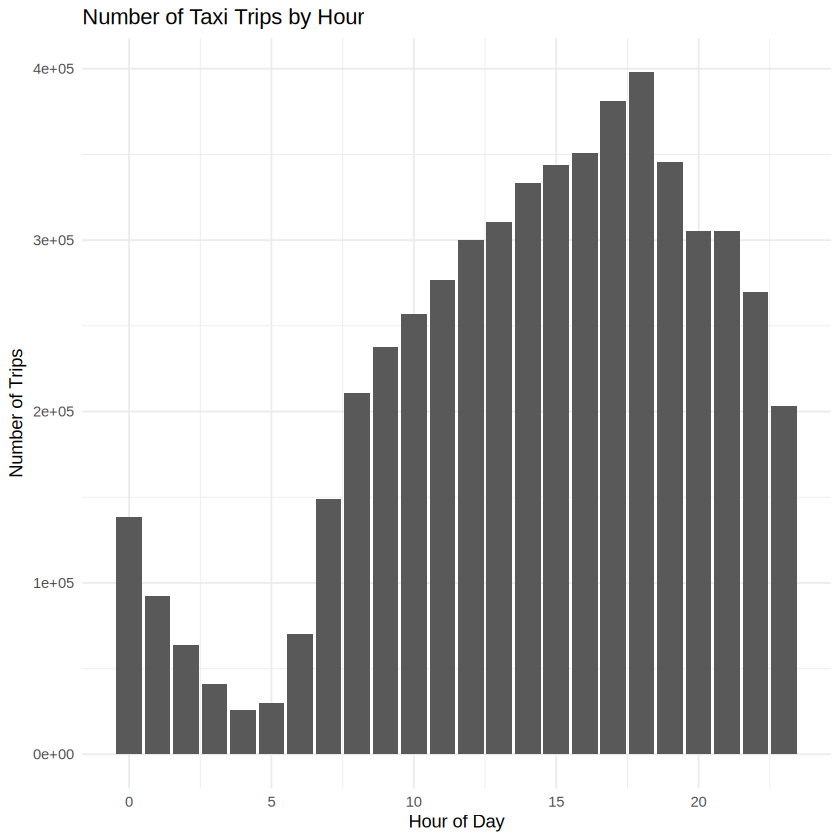

In [24]:
ggplot(trips_by_hour,aes(x=hour,y=trips))+
  geom_col()+
  labs(title="Number of Taxi Trips by Hour",x="Hour of Day",y="Number of Trips")+
  theme_minimal()

## 26. Visualization: Taxi Demand by Day of Week

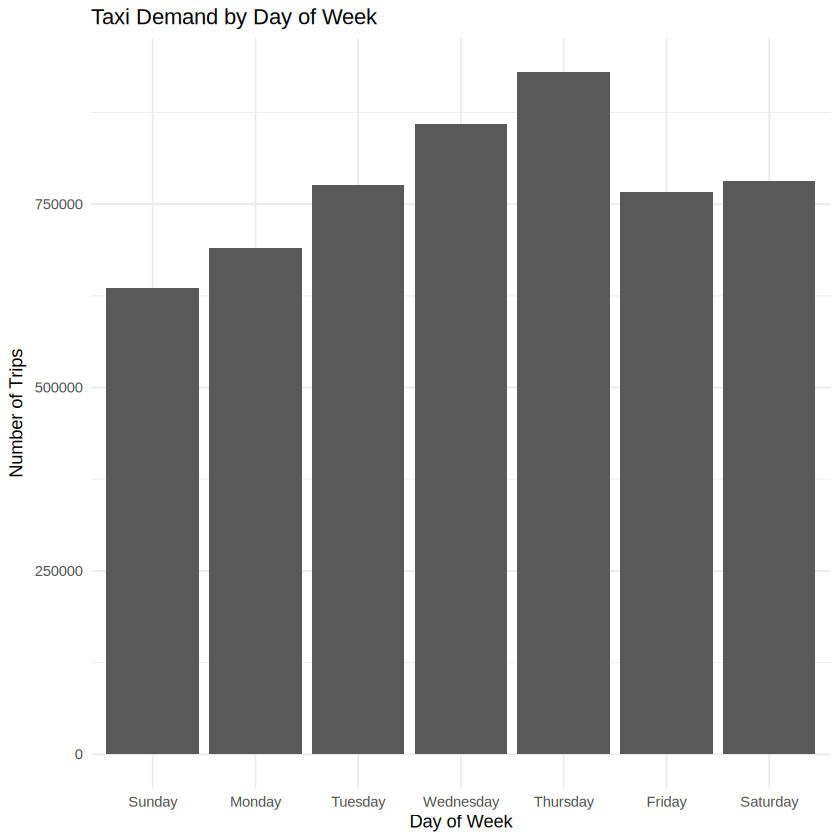

In [25]:
ggplot(trips_by_day,aes(x=day_of_week,y=trips))+
  geom_col()+
  labs(title="Taxi Demand by Day of Week",x="Day of Week",y="Number of Trips")+
  theme_minimal()

## 27. Visualization: Monthly Taxi Demand

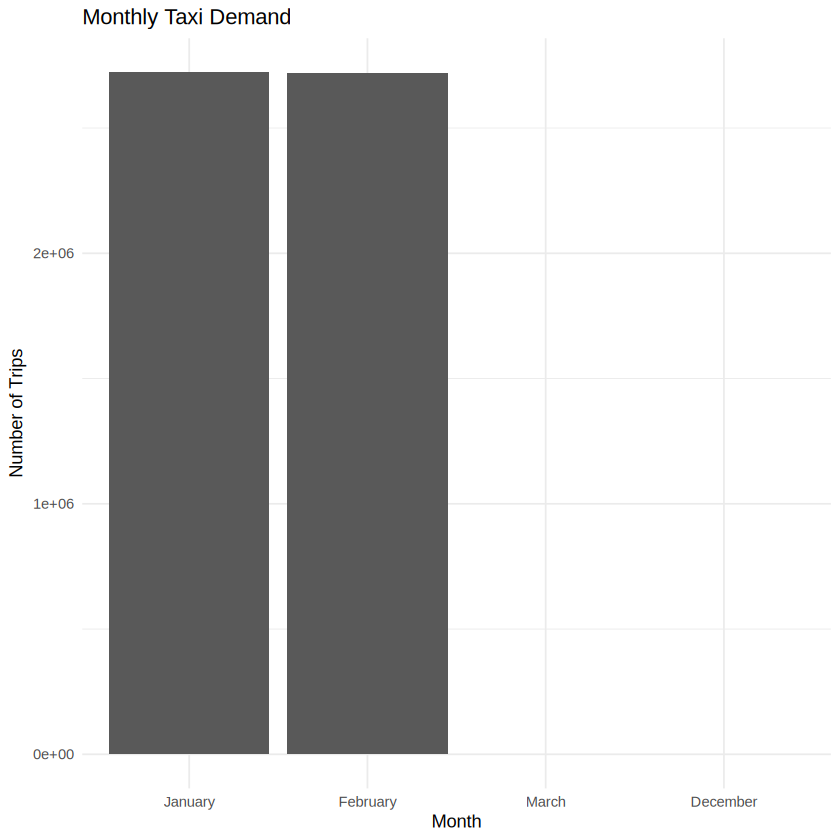

In [26]:
ggplot(monthly_demand,aes(x=factor(month),y=trips))+
  geom_col()+
  labs(title="Monthly Taxi Demand",x="Month",y="Number of Trips")+
  theme_minimal()

## 28. Visualization: Average Fare by Hour

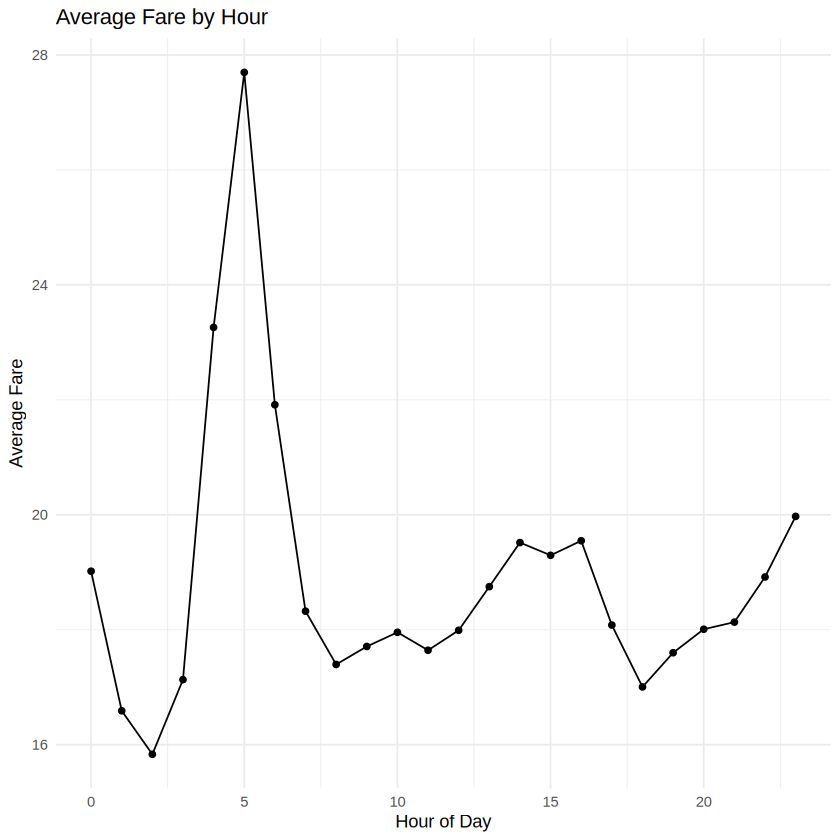

In [27]:
ggplot(hour_summary,aes(x=hour,y=average_fare))+
  geom_line()+
  geom_point()+
  labs(title="Average Fare by Hour",x="Hour of Day",y="Average Fare")+
  theme_minimal()

## 29. Visualization: Revenue by Hour

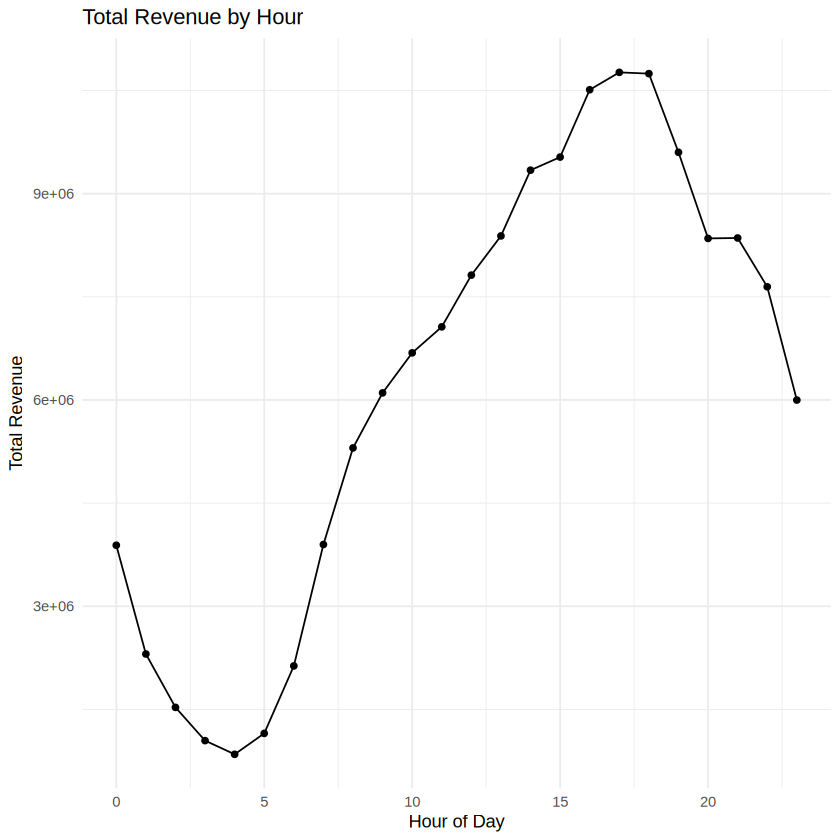

In [28]:
ggplot(hour_summary,aes(x=hour,y=total_revenue))+
  geom_line()+
  geom_point()+
  labs(title="Total Revenue by Hour",x="Hour of Day",y="Total Revenue")+
  theme_minimal()

## 30. Visualization: Trip Distance vs Fare

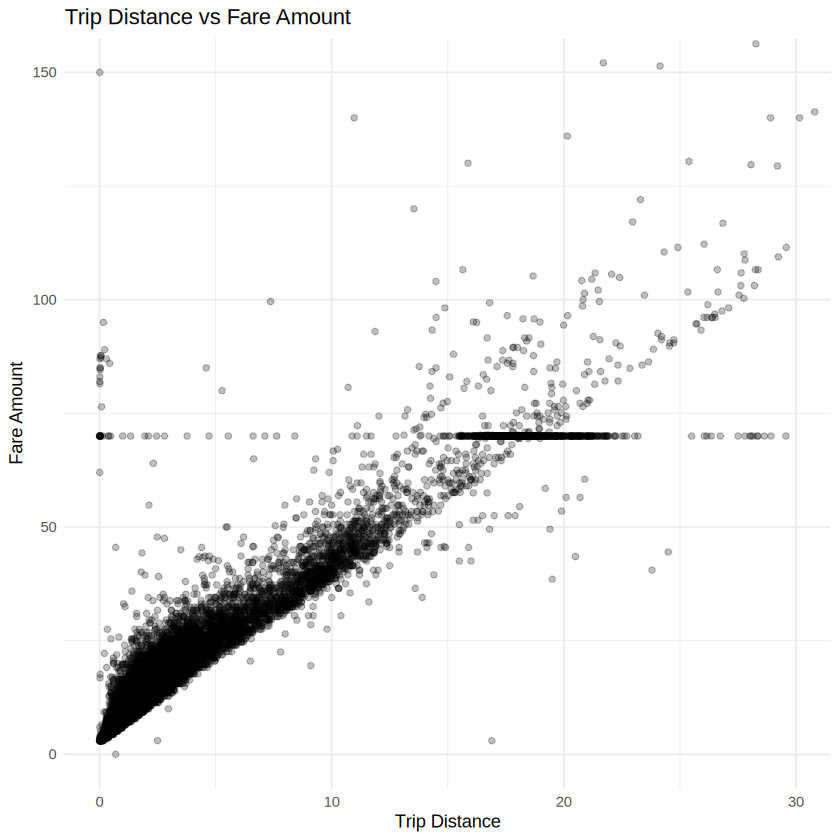

In [29]:
set.seed(42)
plot_data <- taxi[sample(.N,min(.N,20000))]
ggplot(plot_data,aes(x=trip_distance,y=fare_amount))+
  geom_point(alpha=.25)+
  coord_cartesian(xlim=c(0,30),ylim=c(0,150))+
  labs(title="Trip Distance vs Fare Amount",x="Trip Distance",y="Fare Amount")+
  theme_minimal()

## 31. Visualization: Payment-Type Distribution

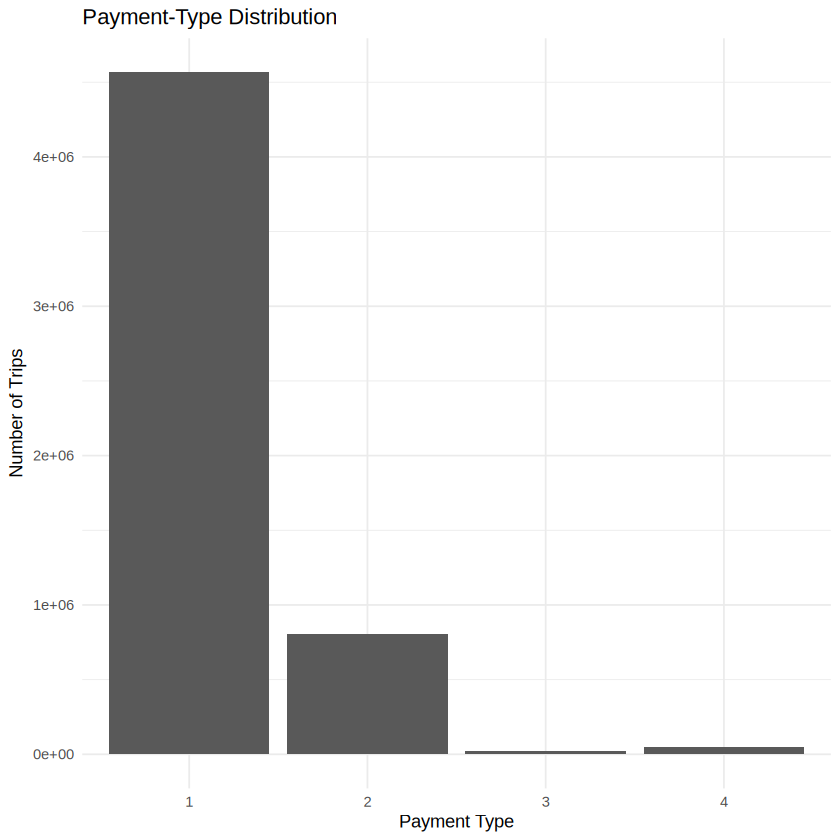

In [30]:
payment_counts <- taxi[,. (trips=.N),by=payment_type]
ggplot(payment_counts,aes(x=factor(payment_type),y=trips))+
  geom_col()+
  labs(title="Payment-Type Distribution",x="Payment Type",y="Number of Trips")+
  theme_minimal()

## 32. Top Pickup Locations

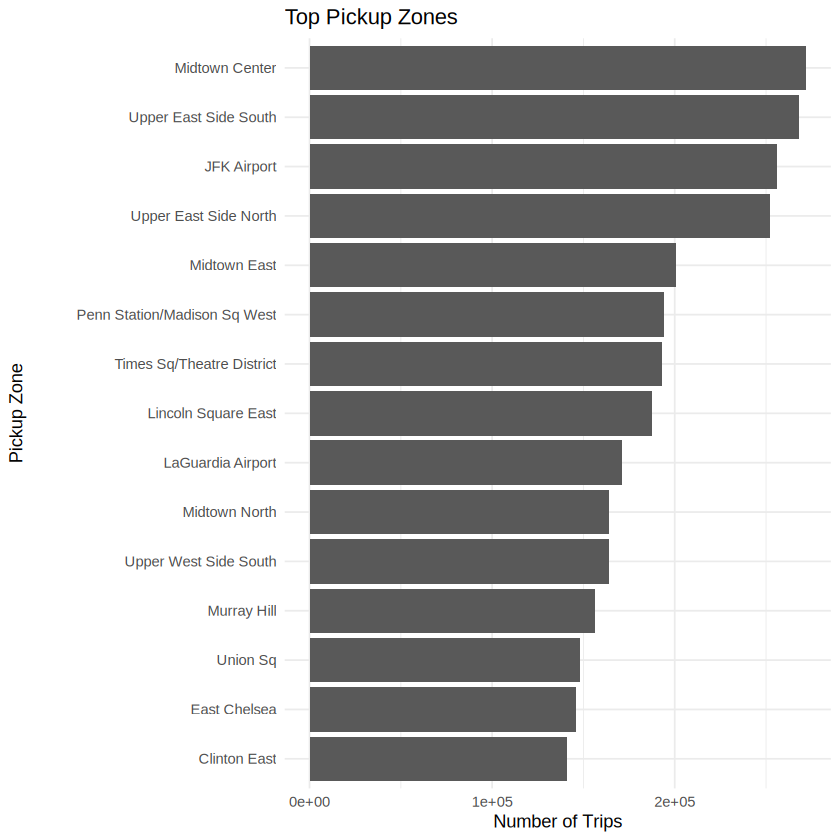

In [31]:
top_pickups <- taxi[,. (trips=.N),by=PUZone][order(-trips)][1:15]
ggplot(top_pickups,aes(x=reorder(PUZone,trips),y=trips))+
  geom_col()+coord_flip()+
  labs(title="Top Pickup Zones",x="Pickup Zone",y="Number of Trips")+
  theme_minimal()

## 33. Top Drop-off Locations

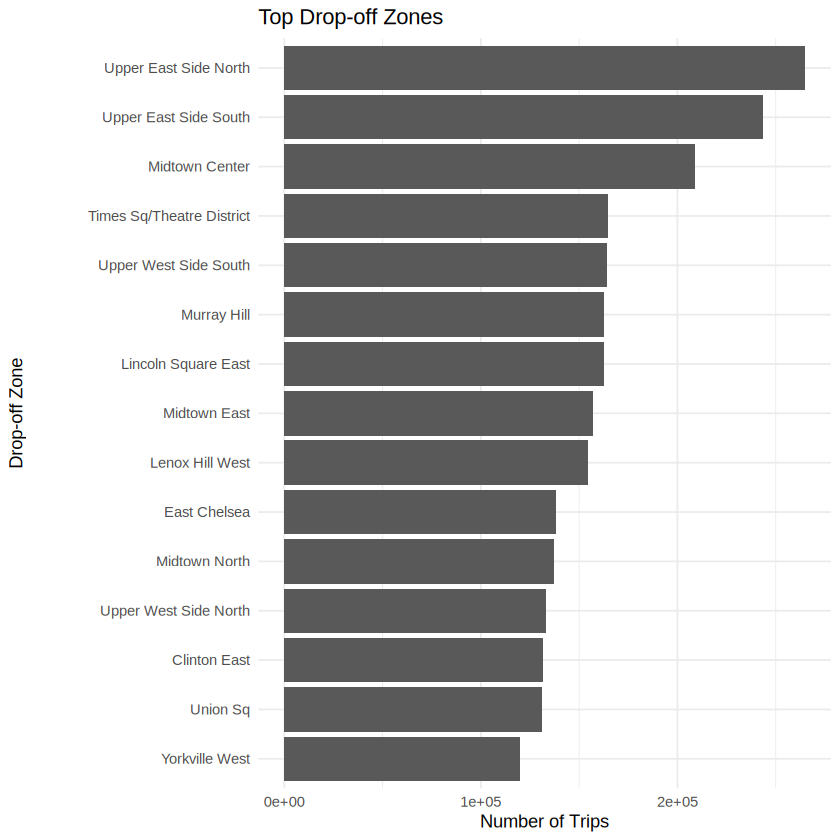

In [32]:
top_dropoffs <- taxi[,. (trips=.N),by=DOZone][order(-trips)][1:15]
ggplot(top_dropoffs,aes(x=reorder(DOZone,trips),y=trips))+
  geom_col()+coord_flip()+
  labs(title="Top Drop-off Zones",x="Drop-off Zone",y="Number of Trips")+
  theme_minimal()

## 34. Critical Performance Analysis

In [33]:
benchmark_summary <- data.table(
  Approach=c("lapply()","Vectorized operations","data.table","Base R aggregate()",
             "data.table grouping","Sequential processing","Parallel processing"),
  Evaluation=c("Functional repeated summaries","Vectorized numeric summary",
               "Efficient aggregation","Grouped aggregation",
               "Optimized grouped aggregation","Month-wise computation",
               "Parallel month-wise computation")
)
print(benchmark_summary)

                Approach                      Evaluation
                  <char>                          <char>
1:              lapply()   Functional repeated summaries
2: Vectorized operations      Vectorized numeric summary
3:            data.table           Efficient aggregation
4:    Base R aggregate()             Grouped aggregation
5:   data.table grouping   Optimized grouped aggregation
6: Sequential processing          Month-wise computation
7:   Parallel processing Parallel month-wise computation


## 35. Observations

- `data.table` is suitable for efficient filtering, joining, grouping and aggregation on large datasets.
- Vectorized operations generally reduce iteration overhead.
- `lapply()` and `purrr::map()` provide concise and reusable functional solutions.
- Parallel processing can improve performance for sufficiently large independent workloads.
- Parallel processing is not always faster because cluster creation and communication add overhead.
- The benchmark results should be used to select the best approach for the actual workload.

## 36. Final Recommendation

For large-scale NYC Taxi analytics, use `data.table` for core data manipulation and aggregation, vectorized operations for numerical calculations, functional programming for reusable repeated operations, and `foreach` with `doParallel` for sufficiently large independent computational tasks. The recommendation should be supported by the measured benchmark and speedup results.

## 37. Conclusion

This experiment demonstrates an end-to-end high-performance analytics workflow in R using NYC TLC Yellow Taxi data. It covers data preparation, `data.table`, functional programming, vectorization, sequential and parallel processing, benchmarking, visualization, and critical performance evaluation.

The results demonstrate why scalable and optimized R approaches are important when working with large real-world transportation datasets.

## 38. Submission Checklist

- Complete R implementation
- Data preprocessing and cleaning
- data.table implementation
- Functional programming
- Vectorized implementation
- Sequential processing
- Parallel processing using foreach and doParallel
- Performance benchmark results
- Execution-time comparison
- ggplot2 visualizations
- Interpretation of analytical findings
- Critical performance analysis
- Final recommendation and conclusion